In [ ]:
#Major Project 1
from sklearn.linear_model import LinearRegression, LogisticRegression
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, accuracy_score
import pandas as pd

<Axes: xlabel='Study_Hours', ylabel='Quiz_Score'>

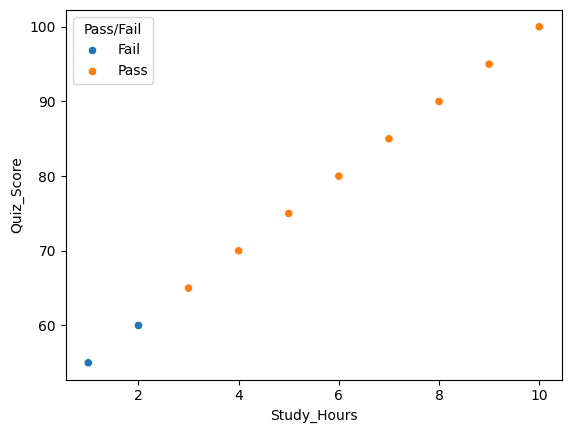

In [ ]:
data = pd.DataFrame({

  'Study_Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],

  'Quiz_Score': [55, 60, 65, 70, 75, 80, 85, 90, 95, 100],

  'Pass/Fail': ['Fail', 'Fail', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass', 'Pass']
})

sns.scatterplot(x=data['Study_Hours'], y = data['Quiz_Score'], hue=data['Pass/Fail'])

In [ ]:
mean = data['Quiz_Score'].mean()
median = data['Quiz_Score'].median()
mode = "No Mode"
print(f'Mean: {mean} \n Median:{median} \n Mode:  {mode}')

Mean: 77.5 
 Median:77.5 
 Mode:  No Mode


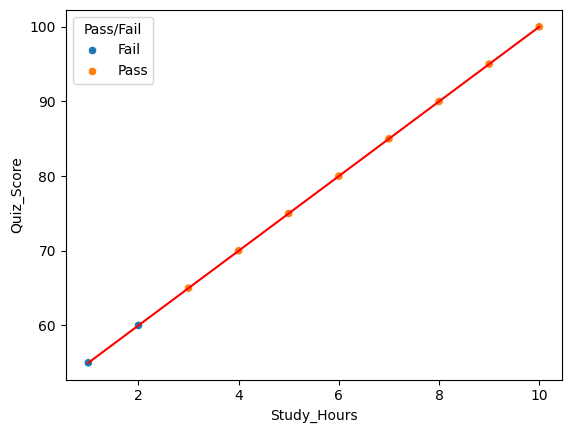

In [ ]:
X = data[['Study_Hours']]
y = data[['Quiz_Score']]
model = LinearRegression()
model.fit(X, y)
pred = model.predict(X)

sns.scatterplot(x=data['Study_Hours'], y = data['Quiz_Score'], hue=data['Pass/Fail'])
plt.plot(data['Study_Hours'],pred, color='red')
r2 = r2_score(y, pred)

In [ ]:

X = data[['Study_Hours']].values
y = data['Pass/Fail']
model2 = LogisticRegression(max_iter=1000)
model2.fit(X, y)

sns.scatterplot(x=data['Study_Hours'], y=data['Pass/Fail'], hue=data['Pass/Fail'])
X_smooth = np.linspace(data['Study_Hours'].min(), data['Study_Hours'].max(), 100).reshape(-1, 1)
y_prob = model2.predict_proba(X_smooth)[:, 1]

plt.plot(X_smooth, y_prob, color='red', label='Probability of Passing')


plt.ylabel('Probability / Outcome')
plt.legend()
plt.show()

pred2 = model2.predict(X)
accuracy_score = accuracy_score(X, pred2)

In [ ]:
data['Predicted_Score'] = pred
data['Predicted_Pass/Fail'] = pred2

proba = model2.predict_proba(X)

data['Pred_Proba_Pass/Fail'] = proba[:, 1]
print(data)

   Study_Hours  Quiz_Score Pass/Fail  Predicted_Score Predicted_Pass/Fail  \
0            1          55      Fail             55.0                Fail   
1            2          60      Fail             60.0                Fail   
2            3          65      Pass             65.0                Pass   
3            4          70      Pass             70.0                Pass   
4            5          75      Pass             75.0                Pass   
5            6          80      Pass             80.0                Pass   
6            7          85      Pass             85.0                Pass   
7            8          90      Pass             90.0                Pass   
8            9          95      Pass             95.0                Pass   
9           10         100      Pass            100.0                Pass   

   Pred_Proba_Pass/Fail  
0              0.176945  
1              0.392246  
2              0.659580  
3              0.853301  
4              0.94583